In [15]:
import joblib
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

preprocessed_data = joblib.load('preprocessed_data.joblib')

X_train = preprocessed_data['X_train']
X_val = preprocessed_data['X_val']
X_test = preprocessed_data['X_test']

y_train = preprocessed_data['y_train']
y_val = preprocessed_data['y_val']
y_test = preprocessed_data['y_test']

In [16]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(n_neighbors=5)

knn_model.fit(X_train, y_train)

KNeighborsRegressor()

In [17]:
y_val_pred_knn = knn_model.predict(X_val)

In [18]:
print(y_val_pred_knn[:10])

[170.4   4.6 341.2 280.4  99.   50.8  12.2 304.  294.   11. ]


In [19]:
mae_knn = mean_absolute_error(y_val, y_val_pred_knn)

rmse_knn = np.sqrt(
    mean_squared_error(y_val, y_val_pred_knn)
)

r2_knn = r2_score(y_val, y_val_pred_knn)

print("KNN MAE:", mae_knn)
print("KNN RMSE:", rmse_knn)
print("KNN R2 Score:", r2_knn)

KNN MAE: 69.27993862677407
KNN RMSE: 101.76682991846234
KNN R2 Score: 0.6800835315135099


In [20]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

k_values = [3, 5, 7, 9, 11, 15, 20]

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    print(f"k = {k}")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2: {r2:.4f}")
    print("--------------------")

k = 3
MAE: 67.25
RMSE: 101.32
R2: 0.6829
--------------------
k = 5
MAE: 69.28
RMSE: 101.77
R2: 0.6801
--------------------
k = 7
MAE: 71.06
RMSE: 101.46
R2: 0.6820
--------------------
k = 9
MAE: 72.20
RMSE: 101.24
R2: 0.6834
--------------------
k = 11
MAE: 72.74
RMSE: 101.45
R2: 0.6821
--------------------
k = 15
MAE: 74.32
RMSE: 102.11
R2: 0.6779
--------------------
k = 20
MAE: 75.27
RMSE: 102.63
R2: 0.6746
--------------------


In [21]:
best_knn = KNeighborsRegressor(n_neighbors=9)

best_knn.fit(X_train, y_train)

y_test_pred_knn = best_knn.predict(X_test)

In [22]:
mae_test = mean_absolute_error(y_test, y_test_pred_knn)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred_knn))
r2_test = r2_score(y_test, y_test_pred_knn)

print("KNN Test MAE:", mae_test)
print("KNN Test RMSE:", rmse_test)
print("KNN Test R2 Score:", r2_test)

KNN Test MAE: 72.07923112986404
KNN Test RMSE: 100.34663484535739
KNN Test R2 Score: 0.6731158174106848


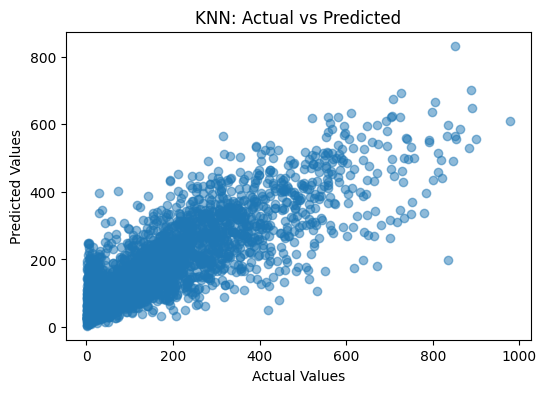

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.scatter(y_test, y_test_pred_knn, alpha=0.5)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("KNN: Actual vs Predicted")

plt.show()

In [24]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

y_test_pred_lr = lr_model.predict(X_test)

In [25]:
mae_lr = mean_absolute_error(y_test, y_test_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))
r2_lr = r2_score(y_test, y_test_pred_lr)

print("Linear Regression Test MAE:", mae_lr)
print("Linear Regression Test RMSE:", rmse_lr)
print("Linear Regression Test R2:", r2_lr)

Linear Regression Test MAE: 75.18208399561213
Linear Regression Test RMSE: 102.00168139041095
Linear Regression Test R2: 0.6622441016968073


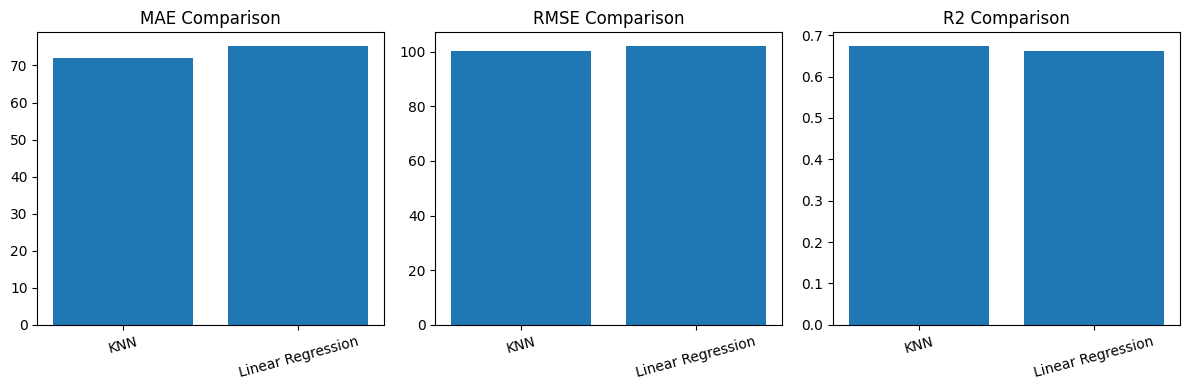

In [26]:
import matplotlib.pyplot as plt

models = ["KNN", "Linear Regression"]

mae_values = [mae_test, mae_lr]
rmse_values = [rmse_test, rmse_lr]
r2_values = [r2_test, r2_lr]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.bar(models, mae_values)
plt.title("MAE Comparison")
plt.xticks(rotation=15)

plt.subplot(1, 3, 2)
plt.bar(models, rmse_values)
plt.title("RMSE Comparison")
plt.xticks(rotation=15)

plt.subplot(1, 3, 3)
plt.bar(models, r2_values)
plt.title("R2 Comparison")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()